# Tópico 16 - Estabilidade no Plano-z

## Visão Geral e Objetivos
Neste notebook, investigamos os critérios de **Estabilidade no Plano-z** para sistemas discretos LTI causais. Os principais objetivos são:
1. **Critério do Círculo Unitário**: Demonstrar que um sistema LTI discreto e causal é BIBO estável se, e somente se, todos os seus polos $p_k$ estiverem localizados estritamente dentro do círculo unitário ($|p_k| < 1$).
2. **Análise dos Regimes Dinâmicos**:
   - $|p_k| < 1$: Sistema Assintoticamente Estável (Resposta transiente atenuada no tempo).
   - $|p_k| = 1$: Sistema Marginalmente Estável (Oscilação senoidal de amplitude constante no tempo).
   - $|p_k| > 1$: Sistema Instável (Envelope exponencial divergente no tempo).
3. **Mapeamento de Polos e Zeros**: Visualizar a posição de polos reais e polos complexos conjugados em relação à fronteira do círculo unitário ($|z| = 1$).
4. **Gerenciamento de Figuras**: Exportar os gráficos gerados diretamente para o diretório local de simulação.

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

# Garantir a criação do diretório local para exportação das imagens
os.makedirs(".", exist_ok=True)

## 1. Definição dos Sistemas e Simulação da Resposta ao Impulso

Avaliamos 4 configurações representativas de sistemas discretos causais:
1. **Estável Real (Polo Simples Interno)**: Polo em $z = 0.6$ ($|p| = 0.6 < 1$).
2. **Estável Oscilatório (Polos Complexos Conjugados Internos)**: Polos em $z = 0.8 e^{\pm j \pi/4}$ ($|p| = 0.8 < 1$).
3. **Marginalmente Estável (Polos sobre o Círculo Unitário)**: Polos em $z = 1.0 e^{\pm j \pi/4}$ ($|p| = 1.0$).
4. **Instável Oscilatório (Polos Complexos Conjugados Externos)**: Polos em $z = 1.1 e^{\pm j \pi/4}$ ($|p| = 1.1 > 1$).

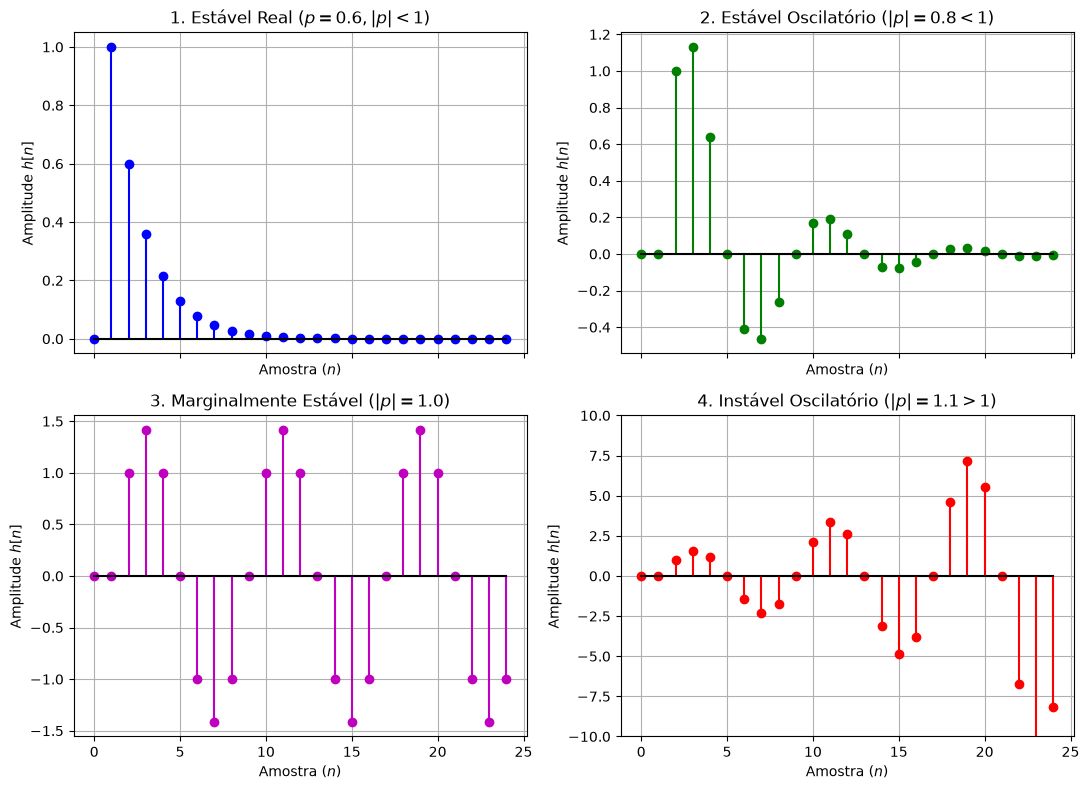

In [2]:
# Número de amostras temporais
N_amostras = 25
n = np.arange(N_amostras)

# Entrada: Impulso Unitário delta[n]
x_imp = np.zeros(N_amostras)
x_imp[0] = 1.0

w0 = np.pi / 4

# Definição dos 4 sistemas discretos causais
sys1 = signal.dlti([1.0], [1.0, -0.6])
sys2 = signal.dlti([1.0], [1.0, -2 * 0.8 * np.cos(w0), 0.8**2])
sys3 = signal.dlti([1.0], [1.0, -2 * 1.0 * np.cos(w0), 1.0**2])
sys4 = signal.dlti([1.0], [1.0, -2 * 1.1 * np.cos(w0), 1.1**2])

sistemas = [sys1, sys2, sys3, sys4]
titulos = [
    r'1. Estável Real ($p = 0.6, |p| < 1$)',
    r'2. Estável Oscilatório ($|p| = 0.8 < 1$)',
    r'3. Marginalmente Estável ($|p| = 1.0$)',
    r'4. Instável Oscilatório ($|p| = 1.1 > 1$)'
]
cores = ['b', 'g', 'm', 'r']

fig1, axs1 = plt.subplots(2, 2, figsize=(11, 8), sharex=True)
axs1 = axs1.flatten()

for idx, sys in enumerate(sistemas):
    t_out, h_n = signal.dlsim(sys, x_imp)
    h_n = np.squeeze(h_n)
    
    axs1[idx].stem(n, h_n, linefmt=f'{cores[idx]}-', markerfmt=f'{cores[idx]}o', basefmt='k-')
    axs1[idx].set_title(titulos[idx])
    axs1[idx].set_xlabel('Amostra ($n$)')
    axs1[idx].set_ylabel('Amplitude $h[n]$')
    axs1[idx].grid(True)
    if idx == 3:
        axs1[idx].set_ylim(-10, 10)

plt.tight_layout()
fig1.savefig("grafico_estabilidade_plano_z_tempo.png")
plt.show()

## 2. Mapeamento de Polos e Zeros no Plano Complexo $z$

Plotamos os diagramas de polos ($\times$) e zeros ($\circ$) para cada um dos 4 sistemas, destacando a fronteira do **círculo unitário** ($|z| = 1$).

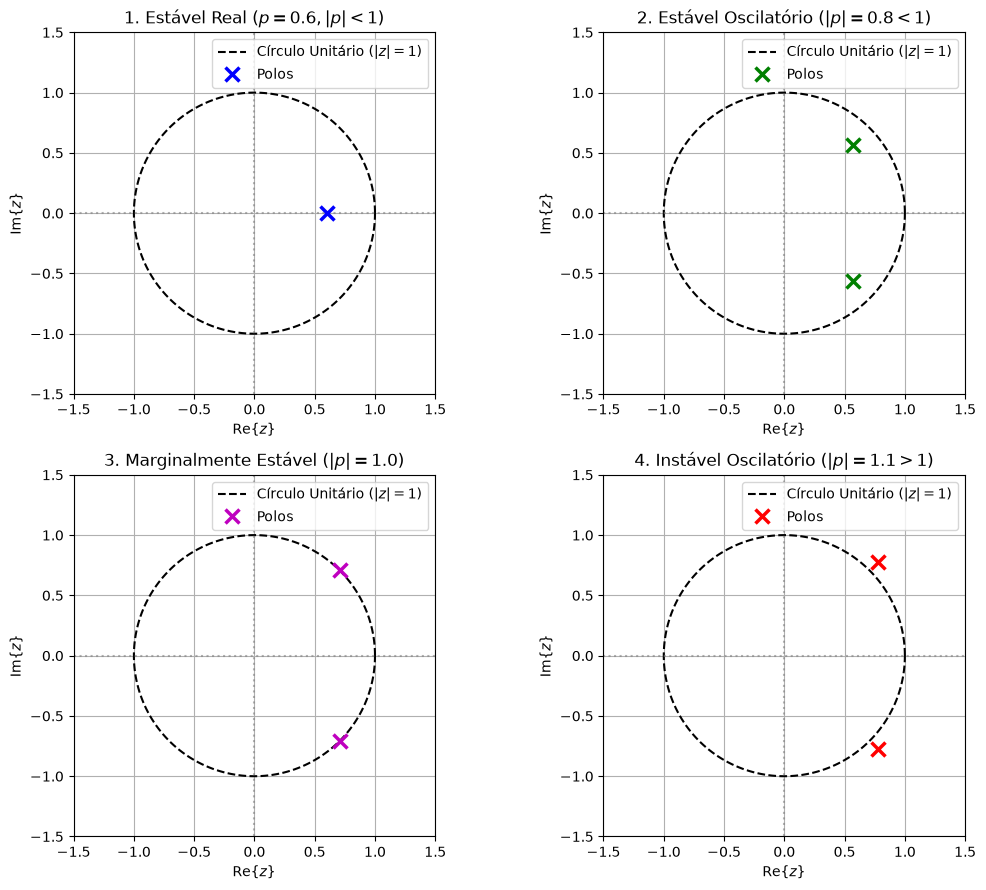

In [3]:
fig2, axs2 = plt.subplots(2, 2, figsize=(11, 9))
axs2 = axs2.flatten()

theta = np.linspace(0, 2 * np.pi, 200)

for idx, sys in enumerate(sistemas):
    polos = sys.poles
    zeros = sys.zeros
    
    # Desenho do Círculo Unitário (|z| = 1)
    axs2[idx].plot(np.cos(theta), np.sin(theta), 'k--', linewidth=1.5, label='Círculo Unitário ($|z|=1$)')
    axs2[idx].axhline(0, color='gray', linestyle=':', alpha=0.6)
    axs2[idx].axvline(0, color='gray', linestyle=':', alpha=0.6)
    
    # Plotar Polos
    axs2[idx].plot(np.real(polos), np.imag(polos), 'x', color=cores[idx], markersize=10, markeredgewidth=2.5, label='Polos')
    if len(zeros) > 0:
        axs2[idx].plot(np.real(zeros), np.imag(zeros), 'o', color=cores[idx], markersize=8, markerfacecolor='none', markeredgewidth=2, label='Zeros')
        
    axs2[idx].set_title(titulos[idx])
    axs2[idx].set_xlabel(r'$\text{Re}\{z\}$')
    axs2[idx].set_ylabel(r'$\text{Im}\{z\}$')
    axs2[idx].set_xlim(-1.5, 1.5)
    axs2[idx].set_ylim(-1.5, 1.5)
    axs2[idx].set_aspect('equal')
    axs2[idx].grid(True)
    axs2[idx].legend(loc='upper right')

plt.tight_layout()
fig2.savefig("grafico_estabilidade_plano_z_mapa.png")
plt.show()

## 3. Síntese dos Resultados sobre Estabilidade no Plano-z
- **Condição Necessária e Suficiente**: Para que um sistema LTI discreto e causal seja BIBO estável, todos os seus polos devem possuir módulo estritamente menor que 1 ($|p_k| < 1$).
- **Estabilidade Marginal ($|p_k| = 1$)**: Polos localizados exatamente sobre o círculo unitário produzem oscilações senoidais de amplitude constante mantidas no tempo, sem atenuação nem divergência.
- **Instabilidade ($|p_k| > 1$)**: Qualquer polo situado fora do círculo unitário provoca o crescimento exponencial ilimitado da resposta temporal ($h[n] \rightarrow \infty$).